# Semantic segmentation with a U-Net

In this practical we train a small **U-Net** to find the **food** on images of hospital meal trays, and we measure how good the result is with the **Dice coefficient**.

**What you will do**
1. Download and look at the *Tray Food Segmentation* dataset
2. Turn the labels into a simple binary task (food vs. not food)
3. Build a U-Net from scratch in PyTorch (~0.5 M parameters)
4. Understand and implement the Dice coefficient
5. Train, evaluate and visualise the predictions

The notebook can be run on a laptop CPU in a few minutes per epoch, or much faster on Google Colab (`Runtime -> Change runtime type -> GPU`).

## 1. Setup

In [2]:
# On Colab everything is already installed. On a laptop you may need:
# pip install torch torchvision kagglehub matplotlib pillow
import random, copy, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():   # Apple Silicon laptops
    device = "mps"
else:
    device = "cpu"
print("Using device:", device)

Using device: mps


## 2. Download the dataset

We use [`kagglehub`](https://github.com/Kaggle/kagglehub) to download the dataset. If it asks for credentials, log in with `kagglehub.login()` or download the zip manually from [Kaggle](https://www.kaggle.com/datasets/thezaza102/tray-food-segmentation) and set `root` to the unzipped folder.

The dataset contains four folders: `XTrain` / `yTrain` (images / masks for training) and `XTest` / `yTest` (images / masks for testing).

In [3]:
# import kagglehub
# root = kagglehub.dataset_download("thezaza102/tray-food-segmentation")
root = "TrayDataset"   # <- use this instead if you downloaded manually

def find_dir(root, name):
    # Return the first sub-folder called `name` anywhere inside `root`
    for p in Path(root).rglob(name):
        if p.is_dir():
            return p
    raise FileNotFoundError(f"No folder called {name} inside {root}")

X_TRAIN, Y_TRAIN = find_dir(root, "XTrain"), find_dir(root, "yTrain")
X_TEST,  Y_TEST  = find_dir(root, "XTest"),  find_dir(root, "yTest")
print(X_TRAIN.parent)

TrayDataset


In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def list_images(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)

def pair_files(img_dir, mask_dir):
    # Match each image with its mask using the file name (without extension)
    imgs  = list_images(img_dir)
    masks = {p.stem: p for p in list_images(mask_dir)}
    pairs = [(p, masks[p.stem]) for p in imgs if p.stem in masks]
    if not pairs:                     # names differ -> fall back to sorted order
        pairs = list(zip(imgs, list_images(mask_dir)))
    return pairs

train_pairs = pair_files(X_TRAIN, Y_TRAIN)
test_pairs  = pair_files(X_TEST,  Y_TEST)
print(f"{len(train_pairs)} training pairs, {len(test_pairs)} test pairs")
print("Example:", train_pairs[0][0].name, "<->", train_pairs[0][1].name)

1241 training pairs, 8 test pairs
Example: 1001a01.jpg <-> 1001a01.png


### Look at one example

Each mask stores, for every pixel, the **index of its class** (0 = background, 1 = tray, 2 = cutlery, ... up to 42 food and drink classes).

Image: (256, 416, 3) | Mask: (256, 416) | values in mask: [ 0  1  2  7 18 19 22 27 31 37 41]
Classes present: ['background', 'tray', 'cutlery', 'roastlamb', 'gravy', 'zucchini', 'pumpkin', 'jacketpotato', 'soup', 'custard', 'orangejuice']


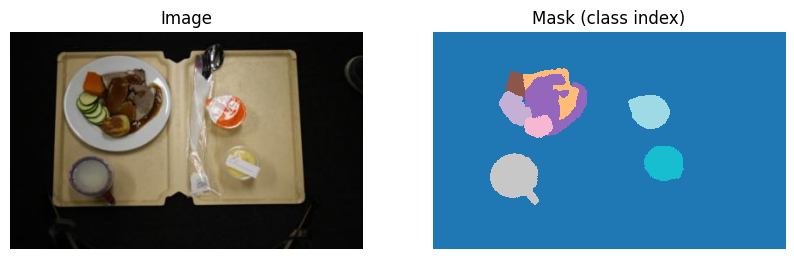

In [5]:
CLASS_NAMES = ['background','tray','cutlery','form','straw','meatball','beef','roastlamb',
               'beeftomatocasserole','ham','bean','cucumber','leaf','tomato','boiledrice',
               'beefmexicanmeatballs','spinachandpumpkinrisotto','bakedfish','gravy','zucchini',
               'carrot','broccoli','pumpkin','celery','sandwich','sidesalad','tartaresauce',
               'jacketpotato','creamedpotato','bread','margarine','soup','apple','cannedfruit',
               'milk','vanillayogurt','jelly','custard','lemonsponge','juice','applejuice',
               'orangejuice','water']

def read_mask(path):
    m = np.array(Image.open(path))
    if m.ndim == 3:          # some masks are saved with 3 identical channels
        m = m[..., 0]
    return m

img_path, mask_path = train_pairs[0]
img, mask = np.array(Image.open(img_path).convert("RGB")), read_mask(mask_path)
print("Image:", img.shape, "| Mask:", mask.shape, "| values in mask:", np.unique(mask))
print("Classes present:", [CLASS_NAMES[v] for v in np.unique(mask) if v < len(CLASS_NAMES)])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(img); ax[0].set_title("Image")
ax[1].imshow(mask, cmap="tab20", interpolation="nearest"); ax[1].set_title("Mask (class index)")
for a in ax: a.axis("off")
plt.show()

## 3. Define the task: food vs. not food

With 43 classes and only ~1,200 images, a tiny network would struggle. To keep things simple we merge the classes into a **binary** problem.

* **0 = not food** → background, tray, cutlery, form, straw (class indices 0 to 4)
* **1 = food** → every class from index 5 onwards

We also resize all images to a small size (128 × 208, which keeps the aspect ratio of the trays) and keep the whole dataset in memory. This makes training fast.

In [6]:
FIRST_FOOD = 5          # class index of 'meatball', the first food class
H, W = 128, 208         # must be divisible by 8 (our U-Net downsamples 3 times)

def load_pairs(pairs):
    X = np.zeros((len(pairs), H, W, 3), dtype=np.uint8)
    Y = np.zeros((len(pairs), H, W),    dtype=np.uint8)
    for i, (ip, mp) in enumerate(pairs):
        X[i] = np.array(Image.open(ip).convert("RGB").resize((W, H), Image.BILINEAR))
        # NEAREST interpolation is essential for masks: we must not invent new class values
        Y[i] = np.array(Image.fromarray(read_mask(mp)).resize((W, H), Image.NEAREST))
    return X, (Y >= FIRST_FOOD).astype(np.uint8)

t0 = time.time()
X_all, Y_all = load_pairs(train_pairs)
X_test, Y_test = load_pairs(test_pairs)
print(f"Loaded in {time.time()-t0:.0f}s | train+val: {X_all.shape} | test: {X_test.shape}")
print(f"Fraction of food pixels: {Y_all.mean():.1%}")

Loaded in 3s | train+val: (1241, 128, 208, 3) | test: (8, 128, 208, 3)
Fraction of food pixels: 10.6%


### Train / validation split and PyTorch `Dataset`

We keep 15% of the training images for **validation** (to choose the best epoch) and use the separate test folder only at the very end. As data augmentation we use a random horizontal flip, applied to the image **and** the mask.

In [7]:
idx = np.random.permutation(len(X_all))
n_val = int(0.15 * len(idx))
val_idx, train_idx = idx[:n_val], idx[n_val:]

class TrayDataset(Dataset):
    def __init__(self, X, Y, augment=False):
        self.X, self.Y, self.augment = X, Y, augment

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).permute(2, 0, 1).float() / 255.0   # (3, H, W) in [0, 1]
        y = torch.from_numpy(self.Y[i]).float().unsqueeze(0)               # (1, H, W) in {0, 1}
        if self.augment and random.random() < 0.5:
            x, y = x.flip(-1), y.flip(-1)
        return x, y

BATCH = 16
train_dl = DataLoader(TrayDataset(X_all[train_idx], Y_all[train_idx], augment=True), batch_size=BATCH, shuffle=True)
val_dl   = DataLoader(TrayDataset(X_all[val_idx],   Y_all[val_idx]),   batch_size=BATCH)
test_dl  = DataLoader(TrayDataset(X_test, Y_test), batch_size=BATCH)
print(f"train: {len(train_idx)} | val: {n_val} | test: {len(X_test)}")

train: 1055 | val: 186 | test: 8


## 4. The U-Net

A U-Net has two halves.

* The **encoder** (left side) repeatedly applies convolutions and max-pooling. The image gets smaller but the number of channels grows, so the network learns *what* is in the image.
* The **decoder** (right side) upsamples back to the original size to say *where* things are.
* **Skip connections** copy the encoder features to the decoder at the same resolution. They give back the fine spatial details lost during pooling. This is the key idea of the U-Net.

```
input (3×128×208)
  enc1 ─────────────────────────────► dec1 ─► 1×1 conv ─► output (1×128×208)
    │ pool                              ▲ up
    enc2 ───────────────────────► dec2
      │ pool                        ▲ up
      enc3 ─────────────────► dec3
        │ pool                ▲ up
        └──── bottleneck ─────┘
```

In [8]:
def conv_block(in_ch, out_ch):
    # Two 3x3 convolutions, each followed by BatchNorm and ReLU
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
    )

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()
        c1, c2, c3, c4 = base, base * 2, base * 4, base * 8
        # Encoder
        self.enc1, self.enc2, self.enc3 = conv_block(in_ch, c1), conv_block(c1, c2), conv_block(c2, c3)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = conv_block(c3, c4)
        # Decoder: upsample, concatenate the skip connection, then convolve
        self.up3, self.dec3 = nn.ConvTranspose2d(c4, c3, 2, stride=2), conv_block(c3 * 2, c3)
        self.up2, self.dec2 = nn.ConvTranspose2d(c3, c2, 2, stride=2), conv_block(c2 * 2, c2)
        self.up1, self.dec1 = nn.ConvTranspose2d(c2, c1, 2, stride=2), conv_block(c1 * 2, c1)
        self.head = nn.Conv2d(c1, out_ch, 1)   # one score (logit) per pixel

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b  = self.bottleneck(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(b),  e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)

model = UNet().to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print("Output shape:", model(torch.zeros(1, 3, H, W, device=device)).shape)

Parameters: 482,737
Output shape: torch.Size([1, 1, 128, 208])


## 5. The Dice coefficient

The Dice coefficient measures the **overlap** between the predicted mask $P$ and the ground truth mask $G$.

$$\text{Dice}(P, G) = \frac{2\,|P \cap G|}{|P| + |G|}$$

It is 1 when the masks match perfectly and 0 when they do not overlap at all. Unlike pixel accuracy, Dice is not fooled by large backgrounds. A model that predicts "no food" everywhere can reach high accuracy but gets a Dice of 0.

Let's compute it by hand on a tiny example first.

In [9]:
P = np.array([[0, 1, 1, 0],
              [0, 1, 1, 0],
              [0, 0, 0, 0],
              [0, 0, 0, 0]])
G = np.array([[0, 0, 1, 1],
              [0, 0, 1, 1],
              [0, 0, 0, 0],
              [0, 0, 0, 0]])
intersection = (P * G).sum()               # pixels that are 1 in both
dice = 2 * intersection / (P.sum() + G.sum())
accuracy = (P == G).mean()
print(f"|P∩G| = {intersection}, |P| = {P.sum()}, |G| = {G.sum()}")
print(f"Dice = {dice:.2f}   vs   pixel accuracy = {accuracy:.2f}")

|P∩G| = 2, |P| = 4, |G| = 4
Dice = 0.50   vs   pixel accuracy = 0.75


Now the PyTorch version, which works on batches. We use it in two ways.

* **Hard Dice** (thresholded 0/1 masks) is the **evaluation metric**.
* **Soft Dice** (probabilities instead of 0/1) is differentiable, so `1 − soft Dice` can be used as a **loss**. We combine it with binary cross-entropy, which is a common and stable choice.

In [10]:
def dice_coef(pred, target, eps=1e-6):
    # pred, target: tensors of shape (B, 1, H, W) with values in [0, 1]. Returns one Dice per image.
    inter = (pred * target).sum(dim=(1, 2, 3))
    total = pred.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return (2 * inter + eps) / (total + eps)

def loss_fn(logits, target):
    probs = torch.sigmoid(logits)
    bce = F.binary_cross_entropy_with_logits(logits, target)
    soft_dice = dice_coef(probs, target).mean()
    return bce + (1 - soft_dice)

@torch.no_grad()
def evaluate(model, loader, threshold=0.5):
    model.eval()
    dices = []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        pred = (torch.sigmoid(model(x)) > threshold).float()   # hard 0/1 mask
        dices.append(dice_coef(pred, y).cpu())
    return torch.cat(dices).numpy()   # Dice for every image

## 6. Training

We train with Adam and keep the weights of the epoch with the best **validation Dice**. On Colab with a GPU, 15 epochs take about a minute. On a laptop CPU, start with fewer epochs.

In [11]:
EPOCHS = 15
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

history = {"train_loss": [], "val_dice": []}
best_dice, best_state = 0.0, None

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, running = time.time(), 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(x)

    train_loss = running / len(train_dl.dataset)
    val_dice = evaluate(model, val_dl).mean()
    history["train_loss"].append(train_loss); history["val_dice"].append(val_dice)

    if val_dice > best_dice:
        best_dice, best_state = val_dice, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:2d} | loss {train_loss:.3f} | val Dice {val_dice:.3f} | {time.time()-t0:.0f}s")

model.load_state_dict(best_state)
print(f"Best validation Dice: {best_dice:.3f}")

Epoch  1 | loss 1.124 | val Dice 0.748 | 12s
Epoch  2 | loss 0.798 | val Dice 0.902 | 6s
Epoch  3 | loss 0.551 | val Dice 0.860 | 6s
Epoch  4 | loss 0.370 | val Dice 0.929 | 7s
Epoch  5 | loss 0.254 | val Dice 0.878 | 7s
Epoch  6 | loss 0.188 | val Dice 0.891 | 6s
Epoch  7 | loss 0.161 | val Dice 0.946 | 6s
Epoch  8 | loss 0.126 | val Dice 0.949 | 6s
Epoch  9 | loss 0.114 | val Dice 0.941 | 6s
Epoch 10 | loss 0.102 | val Dice 0.956 | 6s
Epoch 11 | loss 0.094 | val Dice 0.943 | 6s
Epoch 12 | loss 0.087 | val Dice 0.951 | 6s
Epoch 13 | loss 0.084 | val Dice 0.959 | 6s
Epoch 14 | loss 0.076 | val Dice 0.963 | 6s
Epoch 15 | loss 0.073 | val Dice 0.956 | 6s
Best validation Dice: 0.963


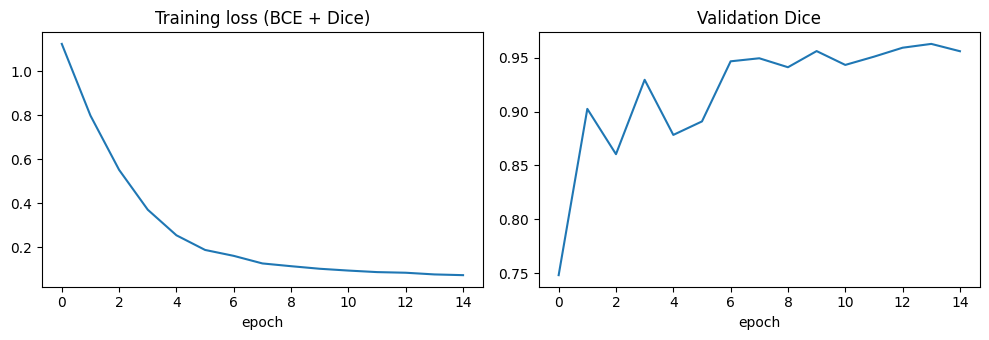

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history["train_loss"]); ax[0].set_title("Training loss (BCE + Dice)"); ax[0].set_xlabel("epoch")
ax[1].plot(history["val_dice"]);   ax[1].set_title("Validation Dice");             ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 7. Evaluation on the test set

In [13]:
test_dice = evaluate(model, test_dl)
print(f"Test Dice: {test_dice.mean():.3f} ± {test_dice.std():.3f}  (n = {len(test_dice)} images)")

Test Dice: 0.943 ± 0.034  (n = 8 images)


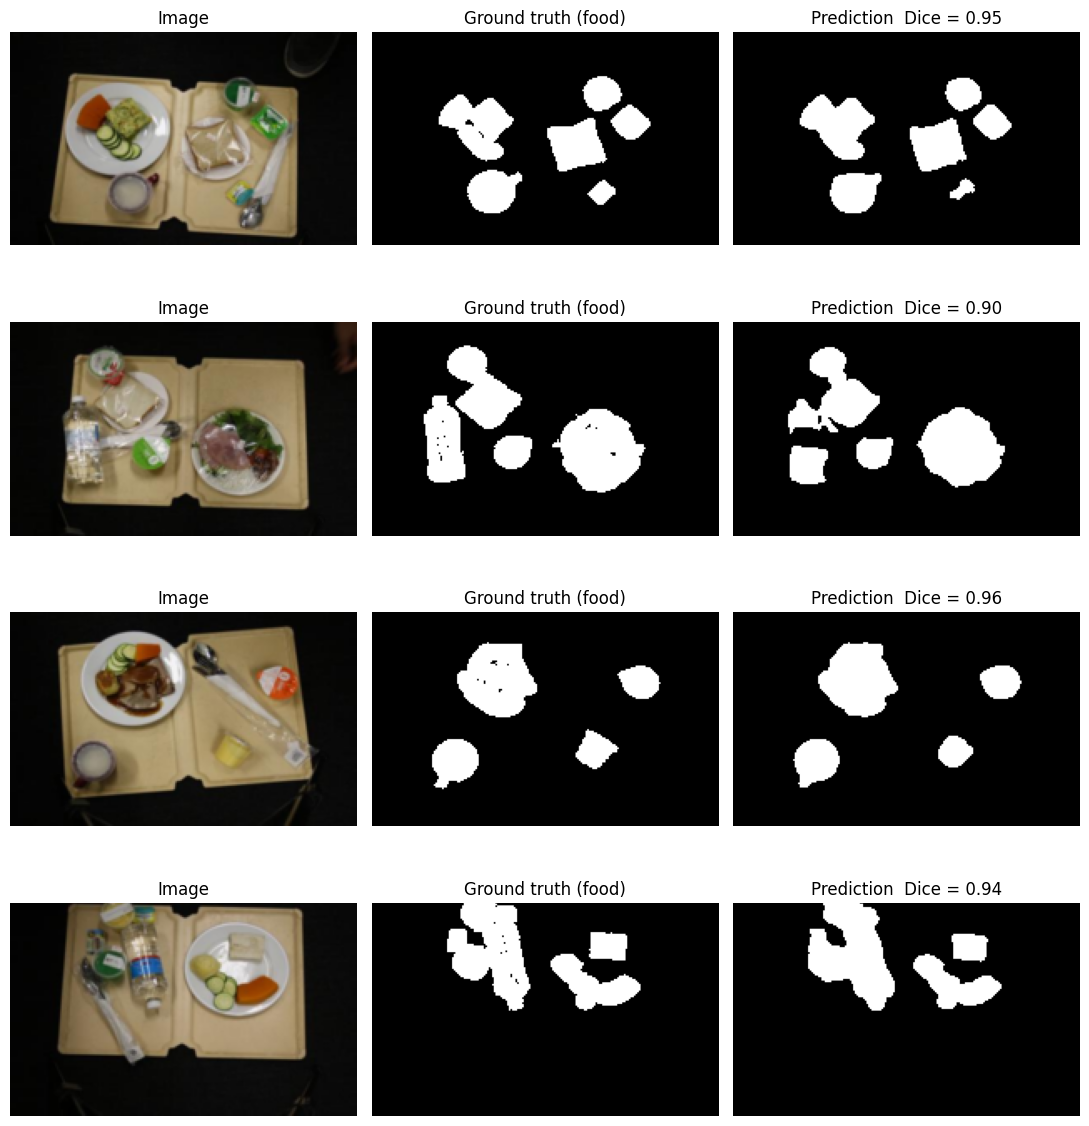

In [14]:
@torch.no_grad()
def show_predictions(X, Y, n=4, threshold=0.5):
    model.eval()
    ids = np.random.choice(len(X), size=min(n, len(X)), replace=False)
    fig, ax = plt.subplots(len(ids), 3, figsize=(11, 3 * len(ids)), squeeze=False)
    for r, i in enumerate(ids):
        x = torch.from_numpy(X[i]).permute(2, 0, 1).float().div(255).unsqueeze(0).to(device)
        pred = (torch.sigmoid(model(x)) > threshold).float().cpu()
        gt = torch.from_numpy(Y[i]).float()[None, None]
        d = dice_coef(pred, gt).item()
        ax[r, 0].imshow(X[i]);                         ax[r, 0].set_title("Image")
        ax[r, 1].imshow(Y[i], cmap="gray");            ax[r, 1].set_title("Ground truth (food)")
        ax[r, 2].imshow(pred[0, 0], cmap="gray");      ax[r, 2].set_title(f"Prediction  Dice = {d:.2f}")
        for a in ax[r]: a.axis("off")
    plt.tight_layout(); plt.show()

show_predictions(X_test, Y_test)

## 8. Exercises

1. **Threshold.** The prediction uses a threshold of 0.5. Try 0.3 and 0.7 with `evaluate(model, val_dl, threshold=...)`. How does Dice change, and why?
2. **Skip connections.** Remove the skip connections (replace `torch.cat([up, e], dim=1)` with just `up` and adjust the channel numbers). Retrain. What happens to the borders of the food regions?
3. **Loss.** Train once with only BCE and once with only the Dice loss. Which converges faster? Which gives the better Dice?
4. **IoU.** Write a function for the Intersection over Union (Jaccard index) $\frac{|P \cap G|}{|P \cup G|}$ and compare it with Dice on the test set. Can you find the formula that converts one into the other?
5. **Worst cases.** Find the 3 validation images with the lowest Dice and display them. What makes them difficult?
6. **(Challenge) Multi-class.** Change the task to predict 3 classes (background, tray, food) with `out_ch=3` and `nn.CrossEntropyLoss`, and report the Dice of each class separately.

## 9. Save the trained model, load it back and test it

This section follows the instructions of **11.1 Segmentation using UNet**:

1. **Train a model and save it.** The model trained in section 6 is written to disk.
2. **Load the model and test it.** A *new* U-Net is built from the file alone, evaluated on the test set, and its segmentations are visualised.

We save a **checkpoint dictionary** rather than the whole Python object. It holds the weights (`state_dict`) and the settings needed to use them again: the architecture parameters, the input size and the threshold. This is the format PyTorch recommends, and it keeps the file loadable even if the notebook changes.

In [15]:
# --- 9.1 Save the trained model -------------------------------------------
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "unet_tray_food.pt"

checkpoint = {
    "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},   # CPU tensors load on any device
    "config": {
        "in_ch": 3, "out_ch": 1, "base": 16,   # must match UNet(...) in section 4
        "H": H, "W": W,                        # input size used during training
        "first_food": FIRST_FOOD,              # class index >= this is "food"
        "threshold": 0.5,
    },
    "val_dice": float(best_dice),
    "test_dice": float(test_dice.mean()),
}
torch.save(checkpoint, MODEL_PATH)
print(f"Saved {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

Saved models/unet_tray_food.pt (2.0 MB)


### 9.2 Load the model

`load_unet` only needs the file. It rebuilds the architecture from the saved `config`, loads the weights and switches to evaluation mode (`model.eval()`), so BatchNorm uses its stored statistics instead of batch statistics.

You can run this cell in a fresh session: run section 1 (imports) and the `UNet` class from section 4 first, then this cell.

In [ ]:
def load_unet(path, map_location=device):
    ckpt = torch.load(path, map_location=map_location, weights_only=True)
    cfg = ckpt["config"]
    net = UNet(in_ch=cfg["in_ch"], out_ch=cfg["out_ch"], base=cfg["base"]).to(map_location)
    net.load_state_dict(ckpt["state_dict"])
    net.eval()
    return net, cfg, ckpt

loaded_model, cfg, ckpt = load_unet(MODEL_PATH)
print("Loaded", MODEL_PATH, "| config:", cfg)
print(f"Dice stored in the checkpoint: val {ckpt['val_dice']:.3f} | test {ckpt['test_dice']:.3f}")

### 9.3 Test the loaded model

First a sanity check. The loaded model must give **the same test Dice** as the model still in memory. If it does not, something went wrong when saving or loading (for example, a different `base` or a forgotten `eval()`).

In [ ]:
loaded_dice = evaluate(loaded_model, test_dl, threshold=cfg["threshold"])
print(f"Test Dice, loaded model:    {loaded_dice.mean():.3f} ± {loaded_dice.std():.3f}")
print(f"Test Dice, model in memory: {test_dice.mean():.3f}")
assert np.allclose(loaded_dice, test_dice, atol=1e-4), "Loaded model does not reproduce the results!"

for (img_path, _), d in zip(test_pairs, loaded_dice):
    print(f"  {img_path.name:12s} Dice = {d:.3f}")

### 9.4 Visualise the segmentation on new images

In a real application the model receives a raw image file, not a pre-processed tensor. `segment_image` does the full pipeline:

1. read the file and resize it to the training size (`W × H`)
2. predict the food probability for each pixel and threshold it
3. resize the mask back to the **original** image size (NEAREST interpolation, so the mask stays 0/1)

We run it on the original test files and show the image, the ground truth, the prediction, and an overlay. Green means correct food, red means food the model invented (false positive) and blue means food it missed (false negative). Dice here is computed at full resolution.

In [ ]:
@torch.no_grad()
def segment_image(net, path, cfg):
    # Return (original RGB image, boolean food mask at original resolution, probability map)
    img = Image.open(path).convert("RGB")
    small = img.resize((cfg["W"], cfg["H"]), Image.BILINEAR)
    x = torch.from_numpy(np.array(small)).permute(2, 0, 1).float().div(255).unsqueeze(0)
    prob = torch.sigmoid(net(x.to(next(net.parameters()).device)))[0, 0].cpu().numpy()
    mask_small = (prob > cfg["threshold"]).astype(np.uint8) * 255
    mask = np.array(Image.fromarray(mask_small).resize(img.size, Image.NEAREST)) > 0
    return np.array(img), mask, prob

def overlay(img, pred, gt=None, alpha=0.5):
    # Colour the prediction on top of the image (green = TP, red = FP, blue = FN)
    out = img.astype(np.float32).copy()
    if gt is None:
        layers = [(pred, (0, 255, 0))]
    else:
        layers = [(pred & gt, (0, 255, 0)), (pred & ~gt, (255, 0, 0)), (~pred & gt, (0, 0, 255))]
    for m, colour in layers:
        out[m] = (1 - alpha) * out[m] + alpha * np.array(colour)
    return out.astype(np.uint8)

def show_segmentations(net, pairs, cfg):
    fig, ax = plt.subplots(len(pairs), 4, figsize=(16, 3 * len(pairs)), squeeze=False)
    for r, (img_path, mask_path) in enumerate(pairs):
        img, pred, _ = segment_image(net, img_path, cfg)
        gt = read_mask(mask_path) >= cfg["first_food"]
        d = 2 * (pred & gt).sum() / (pred.sum() + gt.sum() + 1e-6)
        ax[r, 0].imshow(img);                   ax[r, 0].set_title(img_path.name)
        ax[r, 1].imshow(gt, cmap="gray");       ax[r, 1].set_title("Ground truth (food)")
        ax[r, 2].imshow(pred, cmap="gray");     ax[r, 2].set_title(f"Prediction  Dice = {d:.2f}")
        ax[r, 3].imshow(overlay(img, pred, gt)); ax[r, 3].set_title("Overlay  TP / FP / FN")
        for a in ax[r]: a.axis("off")
    plt.tight_layout(); plt.show()

show_segmentations(loaded_model, test_pairs, cfg)

### 9.5 Segment any image

To use the model on an image that has no ground truth, for example your own photo of a tray, just pass its path. The overlay then shows the predicted food in green.

In [ ]:
path = test_pairs[0][0]   # <- replace with the path to any image, e.g. Path("my_tray.jpg")
img, pred, prob = segment_image(loaded_model, path, cfg)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(img);                       ax[0].set_title(Path(path).name)
im = ax[1].imshow(prob, cmap="magma", vmin=0, vmax=1); ax[1].set_title("Food probability")
ax[2].imshow(overlay(img, pred));        ax[2].set_title(f"Predicted food ({pred.mean():.1%} of pixels)")
fig.colorbar(im, ax=ax[1], fraction=0.03)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()